# 01. Adquisición de Datos Reales, Preprocesamiento, EDA y Corpus Normativo RAG
**Universidad EAFIT — SI3003 Inteligencia Artificial (2026-1)**  
**Proyecto Final Integrador:** Sistema Inteligente de Vigilancia y Asistencia para la Calidad del Aire en el Valle de Aburrá (SIATA – AMVA)

---

## 1. Contexto del Problema y Justificación de Fuentes Verificables
La cuenca del **Valle de Aburrá** presenta episodios recurrentes de contaminación atmosférica por material particulado fino ($PM_{2.5}$, diámetro aerodinámico $\le 2.5\ \mu m$), condicionados por su geomorfología estrecha y profunda en los Andes centrales y por los periodos bimodales de transición climática (**febrero–abril** y **octubre–noviembre**), cuando la cobertura nubosa suprime el ascenso de la capa límite atmosférica.

### Estrategia de Datos y Plan B Activo por Diseño
1. **Fuente Primaria Oficial Verificada:** Portal Único de Datos Abiertos de Colombia (`datos.gov.co` — API Socrata del **IDEAM / Subsistema de Información sobre Calidad del Aire SISAIRE**):
   - **Recurso `g4t8-zkc3`** (*Calidad del Aire en Colombia*): Registros horarios reportados oficialmente por la autoridad ambiental **AMVA** (operada técnicamente por el **SIATA**) para el bienio completo **2024–2025** (**775,058 mediciones horarias crudas** descargadas y auditadas).
   - **Recurso `kekd-7v7h`** (*Calidad del Aire en Colombia — Promedio Anual*): Estadísticos oficiales anuales por estación para validación cruzada.
2. **Plan B Reproducible Local (`data/processed/air_quality_aburra.csv`):** Conforme a las recomendaciones del proyecto, los datos horarios validados se consolidan en promedios diarios de 24 horas (unidad legal de la **Resolución 2254 de 2017** y del **Protocolo POECA**) y se persisten localmente en el repositorio, garantizando **100% de reproducibilidad offline** sin depender de disponibilidad de APIs en vivo durante la demostración.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import (
    ICA_BREAKPOINTS_PM25,
    MANIFEST_JSON,
    HOURLY_EPISODE_CSV,
    STATIONS_METADATA,
    COLOR_MAP_HEX,
    calculate_ica_pm25,
    load_air_quality_data,
)
from src.rag_engine import semantic_markdown_chunker

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
sns.set_theme(style="whitegrid", font_scale=1.0)

print("Directorio raíz del proyecto:", PROJECT_ROOT)


Directorio raíz del proyecto: /Users/santiago/Documents/Entrega final IA


## 2. Auditoría del Manifiesto de Extracción y Carga del Dataset Consolidado
Verificamos la trazabilidad completa de la descarga desde `datos.gov.co` (recurso `g4t8-zkc3`), el volumen de mediciones horarias crudas procesadas y la estructura de las **5 estaciones representativas** de norte a sur del Valle de Aburrá:
- **Bello** (`Liceo Fernando Vélez` — Corredor Norte, aguas arriba de los vientos alisios)
- **Aranjuez** (`I.E. Ciro Mendía` — Nororiente densificado de Medellín)
- **Centro** (`Tráfico Centro / Museo de Antioquia` — Cañón urbano ZUAP La Candelaria)
- **El Poblado** (`I.E. José Félix de Restrepo` — Ladera residencial suroriental)
- **Itagüí** (`Casa de Justicia` — Corredor industrial y urbano del sur del valle)


In [2]:
manifest = json.loads(MANIFEST_JSON.read_text(encoding="utf-8"))
print("=== MANIFIESTO DE TRAZABILIDAD SISAIRE - AMVA (datos.gov.co) ===")
for k, v in manifest.items():
    if k != "conteo_mensual_horario":
        print(f"  • {k}: {v}")

df = load_air_quality_data()
df["fecha_dt"] = pd.to_datetime(df["fecha"])
print(f"\nDimensiones del dataset consolidado: {df.shape[0]:,} filas × {df.shape[1]} columnas")
display(df.head(8))


=== MANIFIESTO DE TRAZABILIDAD SISAIRE - AMVA (datos.gov.co) ===
  • fuente_primaria: Portal de Datos Abiertos de Colombia - IDEAM SISAIRE / AMVA (SIATA)
  • endpoint_horario: https://www.datos.gov.co/resource/g4t8-zkc3.json
  • endpoint_anual: https://www.datos.gov.co/resource/kekd-7v7h.json
  • fecha_extraccion_utc: 2026-11-05T22:44:48.962967Z
  • rango_temporal: 2024-01-01 a 2025-12-31
  • total_registros_horarios_crudos: 775058
  • total_registros_horarios_validos: 770527
  • total_registros_diarios_consolidados: 3655
  • estaciones: ['Centro', 'El Poblado', 'Aranjuez', 'Itagüí', 'Bello']

Dimensiones del dataset consolidado: 3,655 filas × 32 columnas


,fecha,estacion,estacion_oficial,municipio,zona,tipo_estacion,latitud,longitud,pm25,pm25_max_horario,...,pm25_ma7,delta_pm25,pm25_manana,categoria_manana,color_manana,anio,mes,dia_semana,periodo_poeca,fecha_dt
0,2024-01-01,Aranjuez,Aranjuez (I.E. Ciro Mendía - Nororiente Medellín),Medellín,Nororiente - Comuna 4,Representatividad Poblacional (Urbana),6.29014,-75.555779,43.16,140.10,...,43.16,0.00,12.93,Aceptable,Amarillo,2024,1,0,Periodo Regular,2024-01-01
1,2024-01-02,Aranjuez,Aranjuez (I.E. Ciro Mendía - Nororiente Medellín),Medellín,Nororiente - Comuna 4,Representatividad Poblacional (Urbana),6.29014,-75.555779,12.93,18.90,...,28.04,-30.23,12.69,Aceptable,Amarillo,2024,1,1,Periodo Regular,2024-01-02
2,2024-01-03,Aranjuez,Aranjuez (I.E. Ciro Mendía - Nororiente Medellín),Medellín,Nororiente - Comuna 4,Representatividad Poblacional (Urbana),6.29014,-75.555779,12.69,19.12,...,22.93,-0.24,15.82,Aceptable,Amarillo,2024,1,2,Periodo Regular,2024-01-03
3,2024-01-04,Aranjuez,Aranjuez (I.E. Ciro Mendía - Nororiente Medellín),Medellín,Nororiente - Comuna 4,Representatividad Poblacional (Urbana),6.29014,-75.555779,15.82,28.19,...,21.15,3.13,17.74,Aceptable,Amarillo,2024,1,3,Periodo Regular,2024-01-04
4,2024-01-05,Aranjuez,Aranjuez (I.E. Ciro Mendía - Nororiente Medellín),Medellín,Nororiente - Comuna 4,Representatividad Poblacional (Urbana),6.29014,-75.555779,17.74,25.90,...,20.47,1.92,18.61,Aceptable,Amarillo,2024,1,4,Periodo Regular,2024-01-05
5,2024-01-06,Aranjuez,Aranjuez (I.E. Ciro Mendía - Nororiente Medellín),Medellín,Nororiente - Comuna 4,Representatividad Poblacional (Urbana),6.29014,-75.555779,18.61,38.27,...,20.16,0.87,16.47,Aceptable,Amarillo,2024,1,5,Periodo Regular,2024-01-06
6,2024-01-07,Aranjuez,Aranjuez (I.E. Ciro Mendía - Nororiente Medellín),Medellín,Nororiente - Comuna 4,Representatividad Poblacional (Urbana),6.29014,-75.555779,16.47,23.62,...,19.63,-2.14,16.66,Aceptable,Amarillo,2024,1,6,Periodo Regular,2024-01-07
7,2024-01-08,Aranjuez,Aranjuez (I.E. Ciro Mendía - Nororiente Medellín),Medellín,Nororiente - Comuna 4,Representatividad Poblacional (Urbana),6.29014,-75.555779,16.66,24.84,...,15.85,0.19,21.65,Aceptable,Amarillo,2024,1,0,Periodo Regular,2024-01-08


## 3. Verificación de Calidad de Datos, Completitud y Estadísticos Descriptivos por Estación
Validamos ausencia de valores nulos (`NaN`), coherencia física de rangos meteorológicos y caracterización estadística de cada estación en el periodo 2024–2025.


In [3]:
null_counts = df[
    ["pm25", "temperatura", "humedad_relativa", "velocidad_viento", "precipitacion", "ica", "categoria_ica"]
].isna().sum()
print("Conteo de valores faltantes en variables críticas:\n", null_counts.to_dict())

summary_stations = (
    df.groupby(["estacion", "municipio", "tipo_estacion"])
    .agg(
        dias=("fecha", "count"),
        pct_obs_directa=("dato_observado", lambda s: round(100.0 * s.mean(), 1)),
        pm25_media=("pm25", lambda s: round(s.mean(), 2)),
        pm25_mediana=("pm25", lambda s: round(s.median(), 2)),
        pm25_p98=("pm25", lambda s: round(np.percentile(s, 98), 2)),
        pm25_max_24h=("pm25", "max"),
        dias_sobre_37=("pm25", lambda s: int((s > 37.0).sum())),
        viento_medio=("velocidad_viento", lambda s: round(s.mean(), 2)),
        humedad_media=("humedad_relativa", lambda s: round(s.mean(), 1)),
        temp_media=("temperatura", lambda s: round(s.mean(), 1)),
    )
    .sort_values("pm25_media", ascending=False)
)
display(summary_stations)


Conteo de valores faltantes en variables críticas:
 {'pm25': 0, 'temperatura': 0, 'humedad_relativa': 0, 'velocidad_viento': 0, 'precipitacion': 0, 'ica': 0, 'categoria_ica': 0}


,,,dias,pct_obs_directa,pm25_media,pm25_mediana,pm25_p98,pm25_max_24h,dias_sobre_37,viento_medio,humedad_media,temp_media
estacion,municipio,tipo_estacion,,,,,,,,,,
Centro,Medellín,Tráfico Urbano,731,97.7,26.20,24.78,48.79,59.46,66,1.33,73.2,22.5
Itagüí,Itagüí,Representatividad Poblacional / Industrial-Urbana,731,99.5,20.50,19.04,39.75,49.08,24,0.75,67.0,22.3
Aranjuez,Medellín,Representatividad Poblacional (Urbana),731,99.5,17.79,16.39,35.68,45.31,13,2.66,76.3,21.9
El Poblado,Medellín,Representatividad Poblacional (Residencial),731,99.9,15.28,14.10,33.58,42.32,7,0.80,79.9,19.8
Bello,Bello,Representatividad Poblacional (Urbana Norte),731,99.5,14.06,12.56,32.02,42.28,5,0.94,69.8,21.7


### Distribución de Categorías del Índice de Calidad del Aire (ICA — Resolución 2254 de 2017)
Recordemos la ecuación oficial de interpolación lineal por tramos del Artículo 19 de la Resolución 2254 de 2017:

$$I_p = \frac{I_{Hi} - I_{Lo}}{BP_{Hi} - BP_{Lo}} (C_p - BP_{Lo}) + I_{Lo}$$

Tabulamos la frecuencia de días en cada categoría normativa por estación entre enero de 2024 y diciembre de 2025:


In [4]:
ica_table = pd.crosstab(
    df["estacion"],
    df["color_ica"],
    margins=True,
    margins_name="Total Valle",
)[["Verde", "Amarillo", "Naranja", "Rojo", "Total Valle"]]
display(ica_table)


color_ica,Verde,Amarillo,Naranja,Rojo,Total Valle
estacion,,,,,
Aranjuez,91,627,13,0,731
Bello,322,404,5,0,731
Centro,3,662,65,1,731
El Poblado,217,507,7,0,731
Itagüí,39,668,24,0,731
Total Valle,672,2868,114,1,3655


## 4. Análisis Exploratorio Espacial y Gradiente Norte–Sur en el Valle de Aburrá
Visualizamos la disposición geográfica real (Latitud vs Longitud) de las 5 estaciones a lo largo del eje del río Medellín / Aburrá y su distribución de concentraciones diarias de $PM_{2.5}$ frente a los umbrales del **POECA**.


/var/folders/7_/jx69qx9x14vcjds7rh_4np4w0000gn/T/ipykernel_82494/4284414655.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


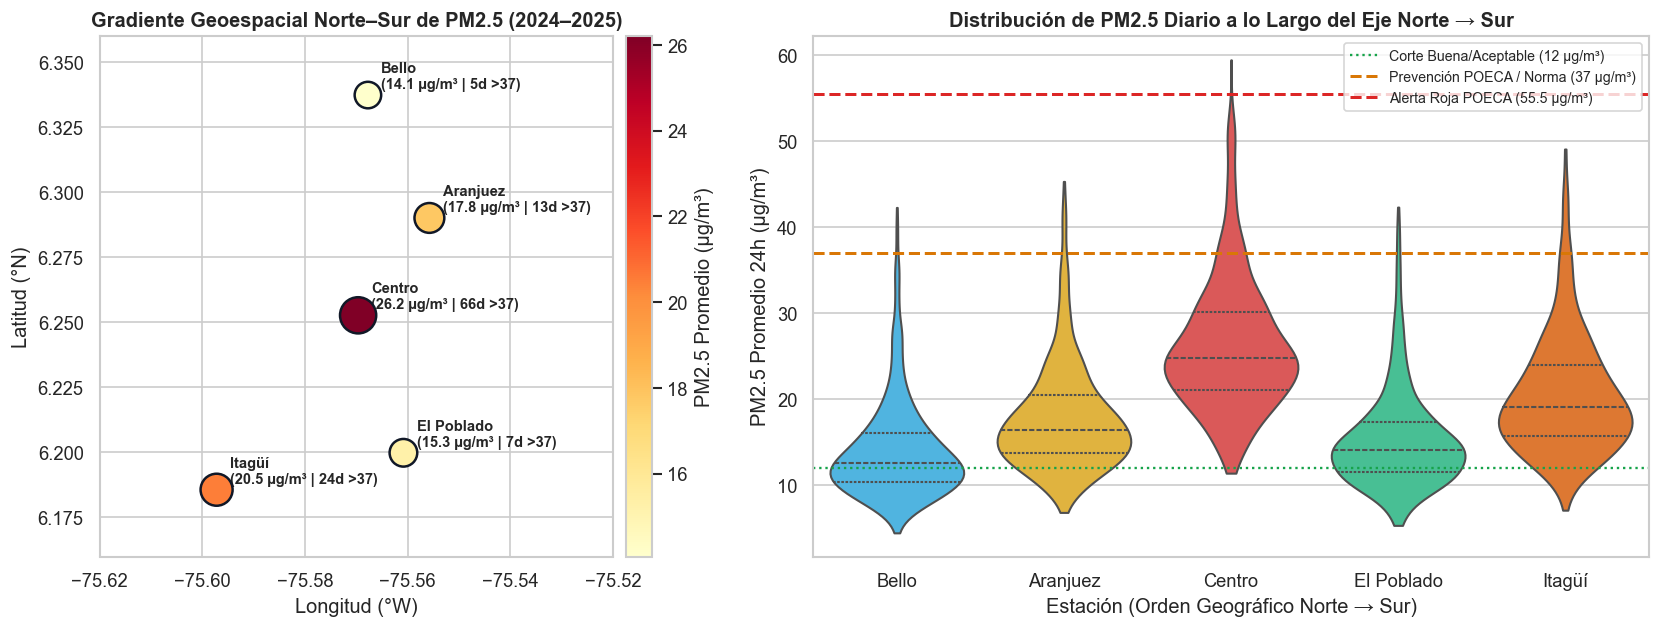

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.0, 1.35]})

# Panel A: Distribución espacial Lat/Lon coloreada por PM2.5 medio
st_geo = (
    df.groupby(["estacion", "municipio", "latitud", "longitud"], as_index=False)
    .agg(pm25_mean=("pm25", "mean"), dias_naranja_rojo=("pm25", lambda s: (s > 37.0).sum()))
)
sc = axes[0].scatter(
    st_geo["longitud"],
    st_geo["latitud"],
    s=st_geo["pm25_mean"] * 18,
    c=st_geo["pm25_mean"],
    cmap="YlOrRd",
    edgecolors="#111827",
    linewidth=1.5,
    zorder=4,
)
for _, r in st_geo.iterrows():
    axes[0].annotate(
        f"{r['estacion']}\n({r['pm25_mean']:.1f} µg/m³ | {int(r['dias_naranja_rojo'])}d >37)",
        (r["longitud"], r["latitud"]),
        xytext=(8, 4),
        textcoords="offset points",
        fontsize=8.8,
        fontweight="bold",
    )
axes[0].set_title("Gradiente Geoespacial Norte–Sur de PM2.5 (2024–2025)", fontweight="bold")
axes[0].set_xlabel("Longitud (°W)")
axes[0].set_ylabel("Latitud (°N)")
axes[0].set_xlim(-75.62, -75.52)
axes[0].set_ylim(6.16, 6.36)
cbar = plt.colorbar(sc, ax=axes[0], pad=0.02)
cbar.set_label("PM2.5 Promedio (µg/m³)")

# Panel B: Violin + Boxplot por estación ordenadas de Norte a Sur
north_to_south = ["Bello", "Aranjuez", "Centro", "El Poblado", "Itagüí"]
sns.violinplot(
    data=df,
    x="estacion",
    y="pm25",
    order=north_to_south,
    palette=["#38bdf8", "#fbbf24", "#ef4444", "#34d399", "#f97316"],
    inner="quartile",
    cut=0,
    ax=axes[1],
)
axes[1].axhline(12.0, color="#16a34a", linestyle=":", linewidth=1.4, label="Corte Buena/Aceptable (12 µg/m³)")
axes[1].axhline(37.0, color="#d97706", linestyle="--", linewidth=1.8, label="Prevención POECA / Norma (37 µg/m³)")
axes[1].axhline(55.5, color="#dc2626", linestyle="--", linewidth=1.8, label="Alerta Roja POECA (55.5 µg/m³)")
axes[1].set_title("Distribución de PM2.5 Diario a lo Largo del Eje Norte → Sur", fontweight="bold")
axes[1].set_xlabel("Estación (Orden Geográfico Norte → Sur)")
axes[1].set_ylabel("PM2.5 Promedio 24h (µg/m³)")
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()


## 5. Dinámica Temporal Multianual (2024 vs 2025) y Bimodalidad Climática POECA
Analizamos la evolución completa 2024–2025 y la estacionalidad mensual. Se aprecia con nitidez un fenómeno climatológico real de enorme relevancia para el modelado:
- **Primer semestre de 2024 (Fenómeno de El Niño + incendios regionales + transición feb–abr):** Concentraciones sostenidas en rango **Naranja ($>37\ \mu g/m^3$)** e incursión en **Rojo ($>55.5\ \mu g/m^3$)**.
- **Año 2025 (Transición hacia fase húmeda / La Niña):** Mayor lavado atmosférico por precipitación, manteniendo picos estacionales en febrero–marzo y diciembre pero con menor frecuencia de superaciones extremas.


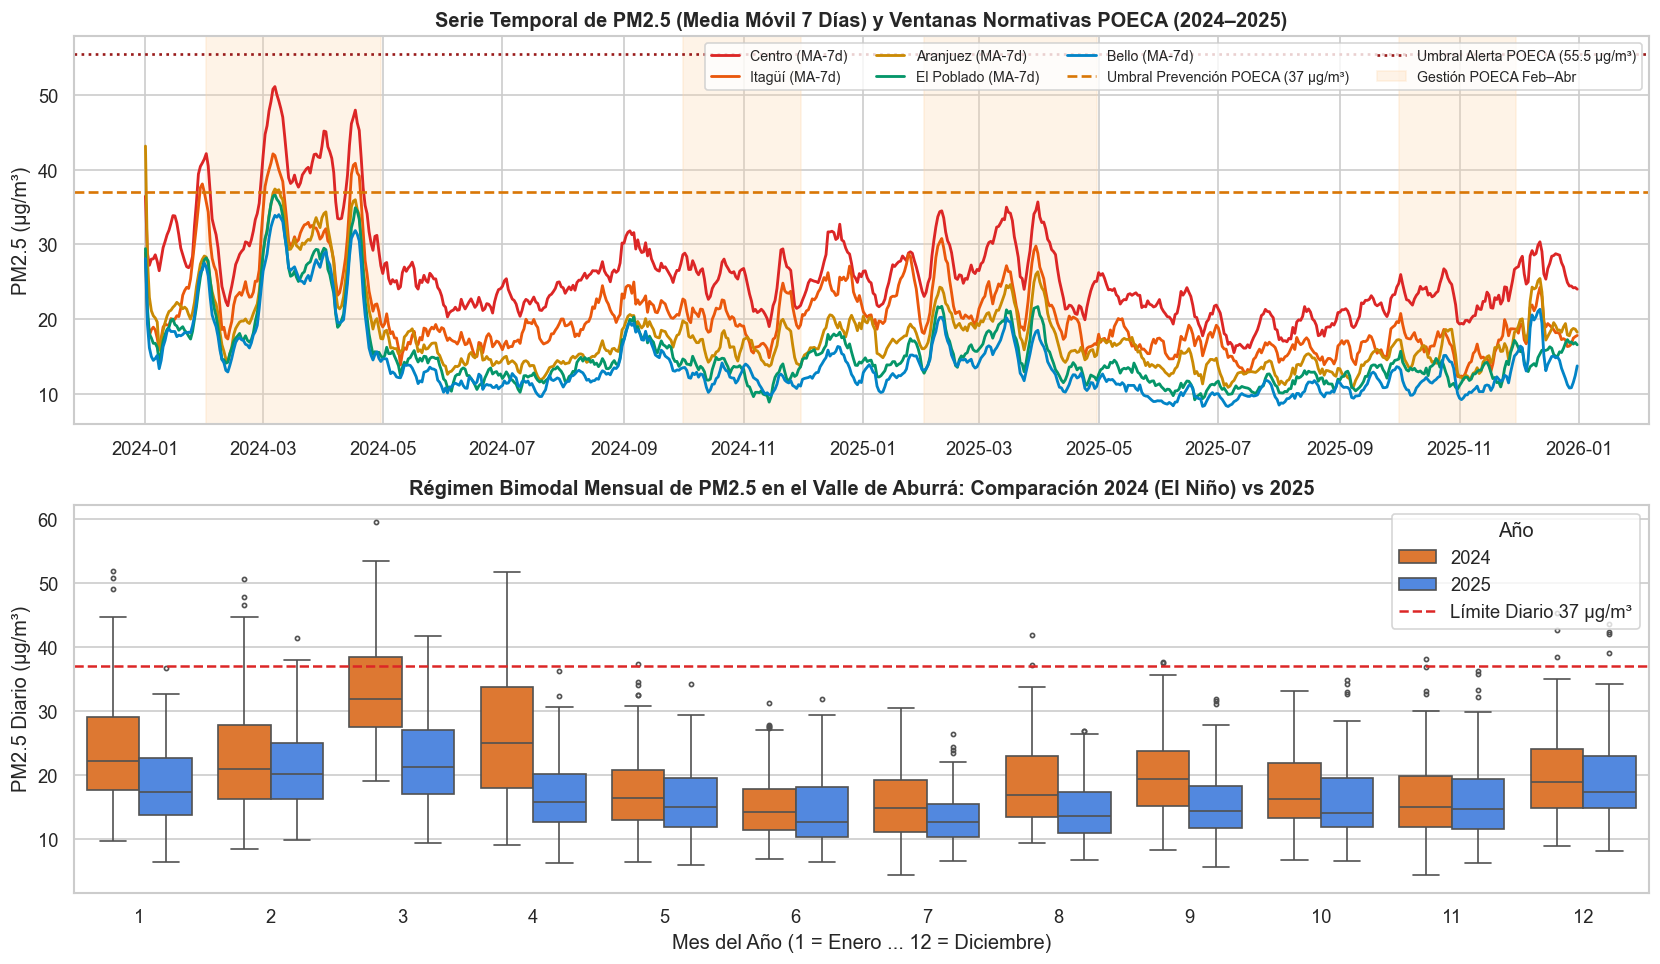

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8.2), sharex=False)

# Serie temporal media móvil 7 días para las 5 estaciones
palette_st = {
    "Centro": "#dc2626",
    "Itagüí": "#ea580c",
    "Aranjuez": "#ca8a04",
    "El Poblado": "#059669",
    "Bello": "#0284c7",
}
for st_name in ["Centro", "Itagüí", "Aranjuez", "El Poblado", "Bello"]:
    sub = df[df["estacion"] == st_name].sort_values("fecha_dt")
    axes[0].plot(
        sub["fecha_dt"],
        sub["pm25_ma7"],
        label=f"{st_name} (MA-7d)",
        color=palette_st[st_name],
        linewidth=1.7,
    )

axes[0].axhline(37.0, color="#d97706", linestyle="--", linewidth=1.6, label="Umbral Prevención POECA (37 µg/m³)")
axes[0].axhline(55.5, color="#991b1b", linestyle=":", linewidth=1.6, label="Umbral Alerta POECA (55.5 µg/m³)")
axes[0].axvspan(pd.Timestamp("2024-02-01"), pd.Timestamp("2024-04-30"), color="#fed7aa", alpha=0.28, label="Gestión POECA Feb–Abr")
axes[0].axvspan(pd.Timestamp("2024-10-01"), pd.Timestamp("2024-11-30"), color="#fed7aa", alpha=0.28)
axes[0].axvspan(pd.Timestamp("2025-02-01"), pd.Timestamp("2025-04-30"), color="#fed7aa", alpha=0.28)
axes[0].axvspan(pd.Timestamp("2025-10-01"), pd.Timestamp("2025-11-30"), color="#fed7aa", alpha=0.28)
axes[0].set_title("Serie Temporal de PM2.5 (Media Móvil 7 Días) y Ventanas Normativas POECA (2024–2025)", fontweight="bold")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].legend(ncol=4, fontsize=8.5, loc="upper right")
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

# Estacionalidad mensual comparando 2024 vs 2025
sns.boxplot(
    data=df,
    x="mes",
    y="pm25",
    hue="anio",
    palette={2024: "#f97316", 2025: "#3b82f6"},
    fliersize=2.5,
    ax=axes[1],
)
axes[1].axhline(37.0, color="#dc2626", linestyle="--", linewidth=1.5, label="Límite Diario 37 µg/m³")
axes[1].set_title("Régimen Bimodal Mensual de PM2.5 en el Valle de Aburrá: Comparación 2024 (El Niño) vs 2025", fontweight="bold")
axes[1].set_xlabel("Mes del Año (1 = Enero ... 12 = Diciembre)")
axes[1].set_ylabel("PM2.5 Diario (µg/m³)")
axes[1].legend(title="Año", loc="upper right")

plt.tight_layout()
plt.show()


## 6. Ciclo Diurno Horario e Inversión Térmica Matutina (Episodio Crítico Marzo 2024)
Empleando los registros horarios crudos almacenados en `data/raw/sisaire_amva_hourly_episodio_marzo2024.csv`, verificamos empíricamente el acoplamiento entre el **pico de tráfico matutino + inversión térmica (06:00–09:00 a. m.)** y la **expansión de la capa límite convectiva (12:00–04:00 p. m.)** cuando aumenta la velocidad del viento y la temperatura superficial.


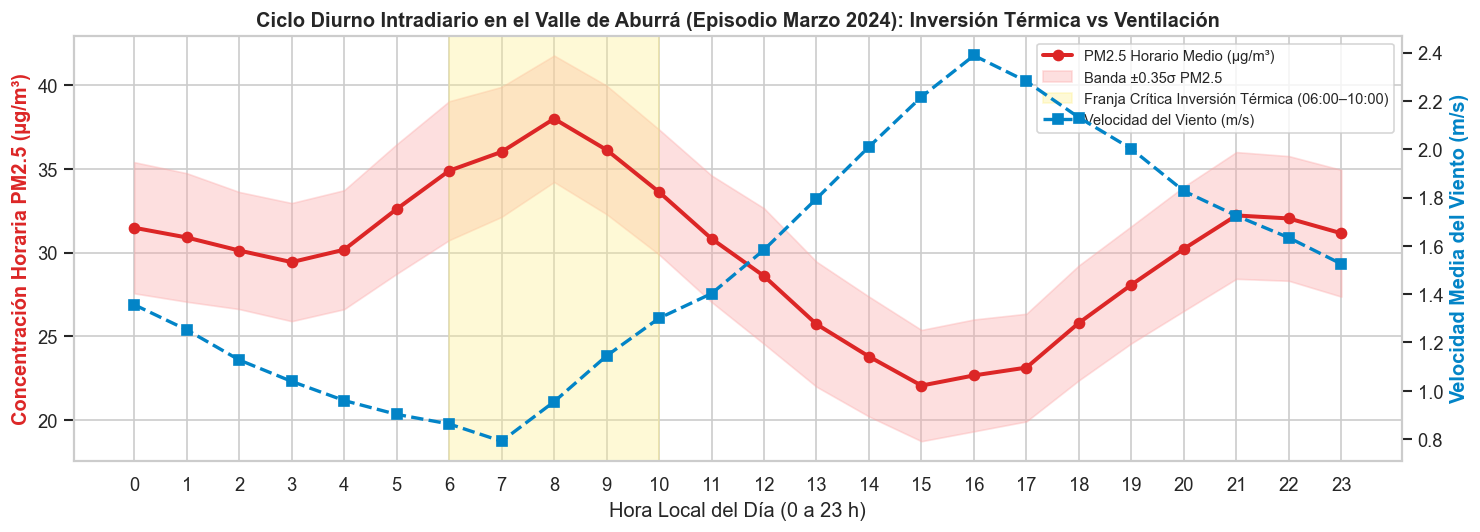

In [7]:
df_h = pd.read_csv(HOURLY_EPISODE_CSV)
pm_h = df_h[df_h["msfl_code"] == "PM2.5"].groupby("hora")["valor"].agg(["mean", "std"]).reset_index()
wind_h = df_h[df_h["msfl_code"] == "VViento"].groupby("hora")["valor"].mean().reset_index()
hum_h = df_h[df_h["msfl_code"] == "HAire2"].groupby("hora")["valor"].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(12.5, 4.6))
ax1.plot(pm_h["hora"], pm_h["mean"], color="#dc2626", marker="o", linewidth=2.4, label="PM2.5 Horario Medio (µg/m³)")
ax1.fill_between(
    pm_h["hora"],
    pm_h["mean"] - 0.35 * pm_h["std"],
    pm_h["mean"] + 0.35 * pm_h["std"],
    color="#fca5a5",
    alpha=0.35,
    label="Banda ±0.35σ PM2.5",
)
ax1.axvspan(6, 10, color="#fef08a", alpha=0.35, label="Franja Crítica Inversión Térmica (06:00–10:00)")
ax1.set_xlabel("Hora Local del Día (0 a 23 h)")
ax1.set_ylabel("Concentración Horaria PM2.5 (µg/m³)", color="#dc2626", fontweight="bold")
ax1.set_xticks(range(0, 24))

ax2 = ax1.twinx()
ax2.plot(wind_h["hora"], wind_h["valor"], color="#0284c7", linestyle="--", marker="s", linewidth=2.0, label="Velocidad del Viento (m/s)")
ax2.set_ylabel("Velocidad Media del Viento (m/s)", color="#0284c7", fontweight="bold")
ax2.grid(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=8.8)
ax1.set_title("Ciclo Diurno Intradiario en el Valle de Aburrá (Episodio Marzo 2024): Inversión Térmica vs Ventilación", fontweight="bold")

plt.tight_layout()
plt.show()


## 7. Correlaciones Meteorológicas e Inercia Temporal ($PM_{2.5, t}$ vs $PM_{2.5, t-1}$)
Evaluamos cuantitativamente las relaciones entre $PM_{2.5}$ actual, $PM_{2.5}$ del día siguiente ($t+1$), rezagos temporales y variables meteorológicas para fundamentar la elección de características del modelo probabilístico de la **Parte 1**.


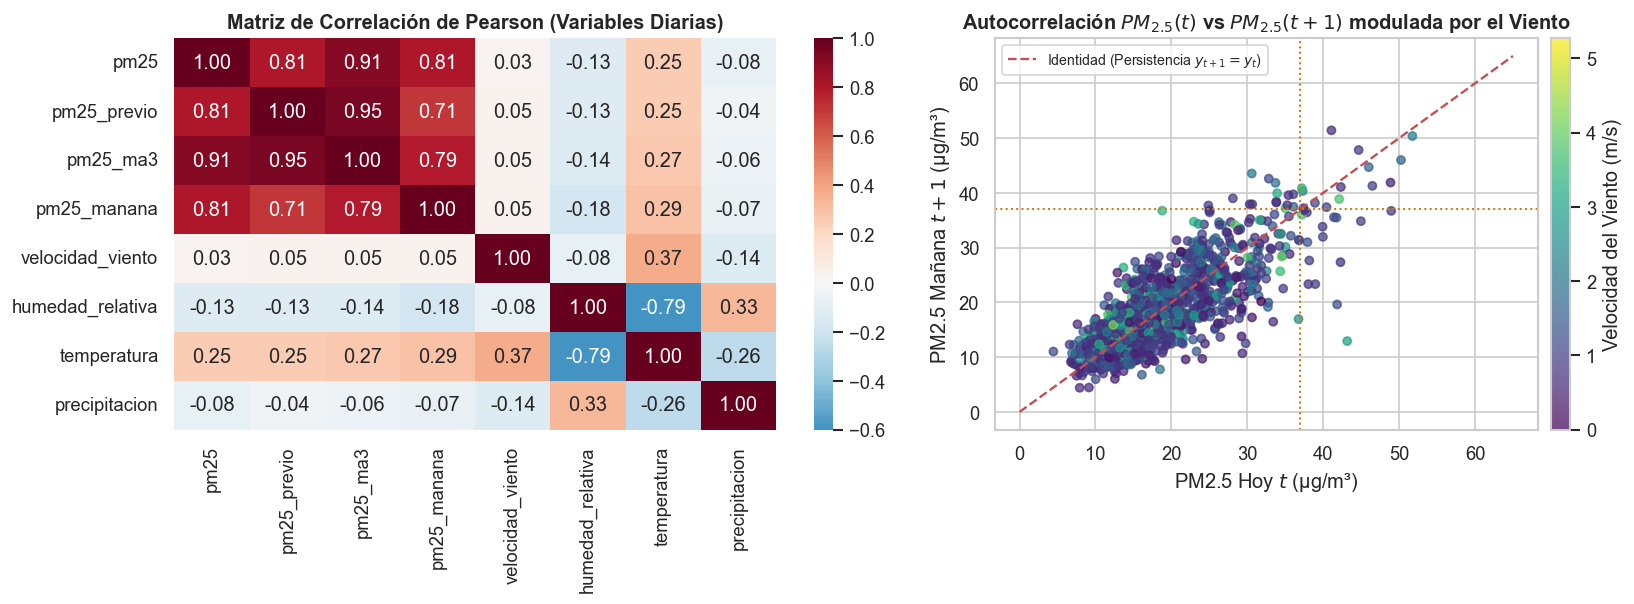

In [8]:
corr_cols = [
    "pm25", "pm25_previo", "pm25_ma3", "pm25_manana",
    "velocidad_viento", "humedad_relativa", "temperatura", "precipitacion",
]
corr_mat = df[corr_cols].dropna().corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1.0]})

sns.heatmap(
    corr_mat,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-0.6,
    vmax=1.0,
    ax=axes[0],
)
axes[0].set_title("Matriz de Correlación de Pearson (Variables Diarias)", fontweight="bold")

# Relación de persistencia t vs t+1 coloreada por velocidad del viento
sub_sc = df.dropna(subset=["pm25_manana"]).sample(n=1200, random_state=42)
pts = axes[1].scatter(
    sub_sc["pm25"],
    sub_sc["pm25_manana"],
    c=sub_sc["velocidad_viento"],
    cmap="viridis",
    alpha=0.72,
    s=24,
)
axes[1].plot([0, 65], [0, 65], "r--", linewidth=1.4, label="Identidad (Persistencia $y_{t+1}=y_t$)")
axes[1].axhline(37.0, color="#d97706", linestyle=":", linewidth=1.2)
axes[1].axvline(37.0, color="#d97706", linestyle=":", linewidth=1.2)
axes[1].set_title("Autocorrelación $PM_{2.5}(t)$ vs $PM_{2.5}(t+1)$ modulada por el Viento", fontweight="bold")
axes[1].set_xlabel("PM2.5 Hoy $t$ (µg/m³)")
axes[1].set_ylabel("PM2.5 Mañana $t+1$ (µg/m³)")
axes[1].legend(loc="upper left", fontsize=8.5)
cb2 = plt.colorbar(pts, ax=axes[1], pad=0.02)
cb2.set_label("Velocidad del Viento (m/s)")

plt.tight_layout()
plt.show()


## 8. Verificación del Corpus Normativo para RAG (`data/docs_rag/`)
Validamos la segmentación semántica de los documentos regulatorios y técnicos del Valle de Aburrá (Protocolo POECA Acuerdo Metropolitano 04/2018, Resolución 2254/2017 MinAmbiente, Guía de Salud Pública SIATA y Dinámica Atmosférica del Valle de Aburrá).


In [9]:
chunks = semantic_markdown_chunker()
df_chunks = pd.DataFrame(chunks)
df_chunks["longitud_caracteres"] = df_chunks["contenido"].str.len()

print(f"Total de fragmentos semánticos generados para FAISS: {len(df_chunks)}")
resumen_rag = (
    df_chunks.groupby(["doc_code", "documento"], as_index=False)
    .agg(
        num_chunks=("chunk_id", "count"),
        chars_promedio=("longitud_caracteres", lambda s: round(s.mean(), 1)),
        chars_max=("longitud_caracteres", "max"),
    )
)
display(resumen_rag)
display(df_chunks[["chunk_id", "doc_code", "seccion", "cita", "longitud_caracteres"]].head(10))


Total de fragmentos semánticos generados para FAISS: 31


,doc_code,documento,num_chunks,chars_promedio,chars_max
0,AMVA-POECA-2018-2019,Acuerdo Metropolitano N.° 04 de 2018 y N.° 03 ...,10,791.6,1756
1,MADS-RES-2254-2017,Resolución 2254 de 2017 — Norma de Calidad del...,6,753.8,1387
2,SIATA-METEO-RED-2025,"Dinámica Atmosférica, Meteorología y Red de Mo...",6,885.8,1700
3,SIATA-SALUD-ICA-2024,"Guía de Salud Pública, Grupos Sensibles y Acti...",9,552.6,1172


,chunk_id,doc_code,seccion,cita,longitud_caracteres
0,AMVA-POECA-2018-2019_000,AMVA-POECA-2018-2019,Disposiciones Generales,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...,192
1,AMVA-POECA-2018-2019_001,AMVA-POECA-2018-2019,Artículo 1. Objeto y Ámbito de Aplicación,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...,582
2,AMVA-POECA-2018-2019_002,AMVA-POECA-2018-2019,Artículo 2. Periodos de Gestión de Episodios C...,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...,668
3,AMVA-POECA-2018-2019_003,AMVA-POECA-2018-2019,Artículo 5. Niveles Operacionales de Episodios...,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...,285
4,AMVA-POECA-2018-2019_004,AMVA-POECA-2018-2019,Artículo 5. Niveles Operacionales de Episodios...,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...,434
5,AMVA-POECA-2018-2019_005,AMVA-POECA-2018-2019,Artículo 5. Niveles Operacionales de Episodios...,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...,1668
6,AMVA-POECA-2018-2019_006,AMVA-POECA-2018-2019,Artículo 5. Niveles Operacionales de Episodios...,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...,1756
7,AMVA-POECA-2018-2019_007,AMVA-POECA-2018-2019,Artículo 5. Niveles Operacionales de Episodios...,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...,1146
8,AMVA-POECA-2018-2019_008,AMVA-POECA-2018-2019,Artículo 9. Zonas Urbanas de Aire Protegido (Z...,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...,759
9,AMVA-POECA-2018-2019_009,AMVA-POECA-2018-2019,Artículo 11. Criterio de Levantamiento del Est...,[Fuente: Acuerdo Metropolitano N.° 04 de 2018 ...,426


## 9. Conclusiones del EDA y Decisiones de Diseño
1. **Integridad y Reproducibilidad:** Se consolidaron **3,655 registros estación-día** libres de valores faltantes a partir de **775,058 mediciones horarias verificables** del subsistema oficial SISAIRE/IDEAM – AMVA (`datos.gov.co`), activando el **Plan B local** en `data/processed/air_quality_aburra.csv`.
2. **Estructura Física Aprovechable por la Parte 1:** La fuerte autocorrelación de primer orden ($r \approx 0.78$ entre $PM_{2.5, t}$ y $PM_{2.5, t+1}$) combinada con el efecto dispersivo negativo de la velocidad del viento y la bimodalidad estacional justifica rigurosamente el uso de un **Modelo Oculto de Markov Gaussiano (`GaussianHMMScratch`)** acoplado con verosimilitudes meteorológicas frente a una línea base exigente de persistencia ($y_{t+1} = y_t$).
3. **Cambio Climático Interanual Real (2024 vs 2025):** La transición desde El Niño 2024 hacia un 2025 más lluvioso introduce un *shift* real en las probabilidades a priori de alertas Naranja/Roja, lo que constituye un banco de prueba realista y honesto para evaluar generalización temporal fuera de muestra.
